# DecisionTree: 머신러닝 분류(Classification) 모델 

# A) 이진 분류 모델 구현 

## 1. 문제 정의 

- 와인의 특성을 통해 레드와인인지 화이트와인인지 예측하는 이진분류 모델을 구현해보자 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

## 2. 데이터 로드 

- 데이터: 와인 데이터
- 포맷: csv 
- feature(특성):
    - alcoho: 알콜 도수 
    - sugar: 당도
    - pH: 산성도
- class: 0.0(레드와인), 1.0(화이트와인)

In [3]:
df = pd.read_csv("https://bit.ly/wine_csv_data")

print(df.shape)
df.head()

(6497, 4)


,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0
2,9.8,2.3,3.26,0.0
3,9.8,1.9,3.16,0.0
4,9.4,1.9,3.51,0.0


In [4]:
df.info()

# 결측치와 object타입의 데이터가 존재하지 않음을 확인

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6497 non-null   float64
 2   pH       6497 non-null   float64
 3   class    6497 non-null   float64
dtypes: float64(4)
memory usage: 203.2 KB


## 3. 데이터 분리

### 3.1 features와 target으로 분리 

In [5]:
X = df.iloc[:, :-1]
y = df[["class"]]

print(X.shape, y.shape)

(6497, 3) (6497, 1)


### 3.2 Train, Test 분리 

1. y.의 값들의 분포 확인하기 

In [6]:
# target의 클래스 분포 확인
y.value_counts() # 클래스 불균형 존재 

class
1.0      4898
0.0      1599
Name: count, dtype: int64

2. train, test 분리 

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(5197, 3) (5197, 1) (1300, 3) (1300, 1)


In [8]:
# 클래스 비율 확인
print(y_train.value_counts(normalize=True))
print()
print(y_test.value_counts(normalize=True))

class
1.0      0.753896
0.0      0.246104
Name: proportion, dtype: float64

class
1.0      0.753846
0.0      0.246154
Name: proportion, dtype: float64


## 4. 전처리 

- DecisionTree는 불순도를 기준으로 샘플을 나누며, 불순도는 클래스별 비율로 계산됨
- 샘플(데이터)을 어떤 클래스 비율로 나누는지 계산할 때 특성값(피처/칼럼)의 스케일은 계산에 아무런 영향을 미치지 않음
- 따라서, DecisionTree는 수치형 데이터를 가진 특성을 표준화 전처리 할 필요가 없음 

## 5. 모델링: max_depth X

### 5.1 모델링 

In [9]:
# 모델 객체 정의 
model = DecisionTreeClassifier(random_state=42)

# 모델 학습 
model.fit(X_train, y_train)

# 성능 평가 (정확도)
print(model.score(X_train, y_train))
print(model.score(X_test, y_test)) # 과적합됐음을 확인할 수 있음

0.9978833942659227
0.87


### 5.2 시각화 

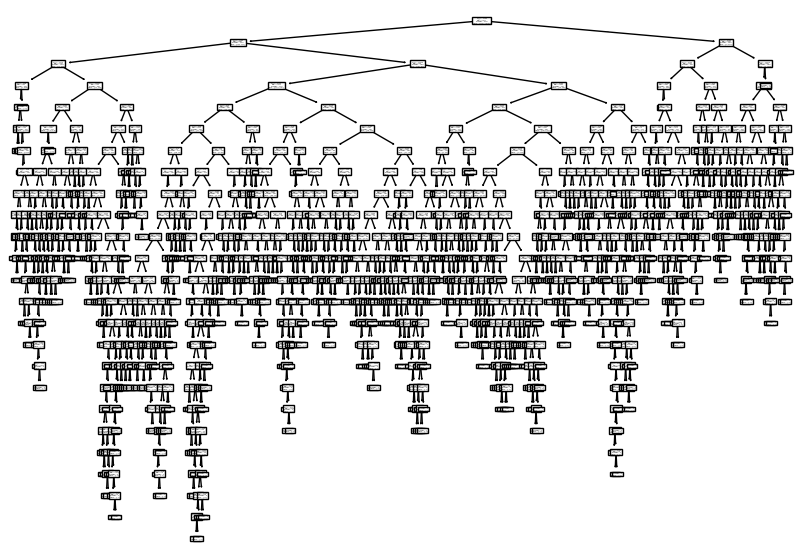

In [10]:
plt.figure(figsize=(10, 7))
plot_tree(model);#######알ㅇㄹㅇㅇㅇㄹㄴㄹㄴㄴㄴㄴㄴㄴㅇㅇㅇㅇㄴㄹㄴㅇㄹㄴㄹㅁㄴㅇㅇㄹㅇㄹㅇㅇㄹㅇㄹㅇㄹ3ㅇㅇㅇㄴㄴㄴ

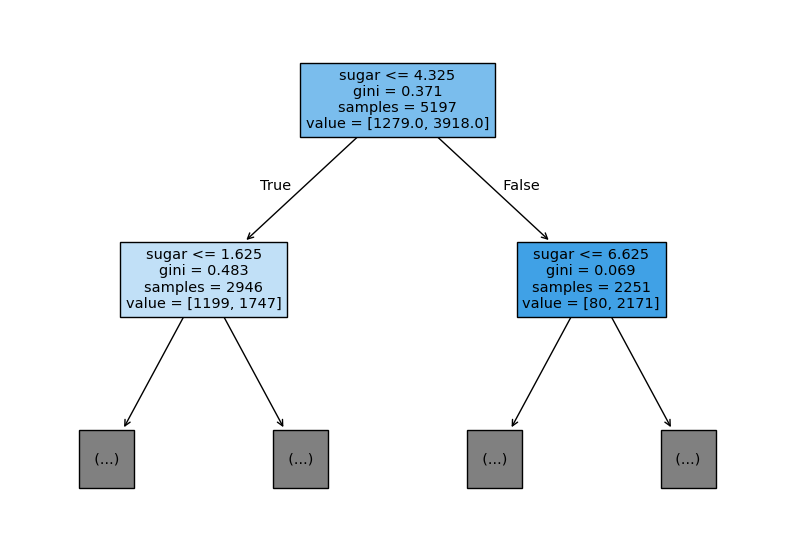

In [11]:
# 상위 노드만 확인해보기 
plt.figure(figsize=(10, 7))

plot_tree(
    model,
    max_depth=1,
    filled=True,    # 트리의 노드(박스) 색상을 클래스별로 채워서 시각적으로 구분하기 쉽게해줌
    feature_names=["alchol", "sugar", "pH"]
);

## 6. 모델링: max_depth O

### 6.1 모델링 

In [ ]:
model_max_depth = DecisionTreeClassifier(max_depth=5, random_state=42)

model_max_depth.fit(X_train, y_train)

print(model_max_depth.score(X_train, y_train))
print(model_max_depth.score(X_test, y_test))

# 성능이 전반적으로 낮아졌지만, 과적합문제는 해결됨을 알 수 있음

0.8718491437367712
0.8576923076923076


### 6.2 시각화 

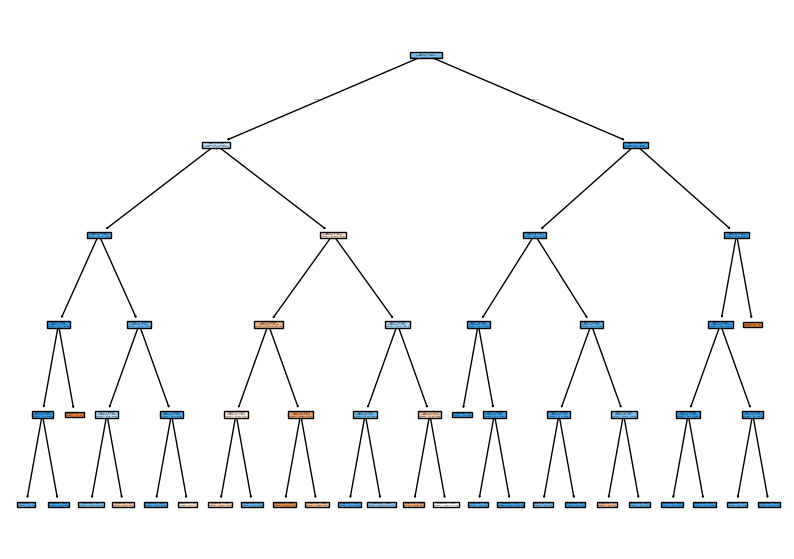

In [13]:
plt.figure(figsize=(10, 7))

plot_tree(
    model_max_depth,
    filled=True,
    feature_names=["alchol", "sugar", "pH"]
);

## 7. max_depth에 따라 정확도 비교해보기 

In [14]:
train_list, test_list = [], []

for i in range(1, 11):
    model = DecisionTreeClassifier(max_depth=i, random_state=42)
    model.fit(X_train, y_train)

    # train 정확도 list에 담기 
    train_list.append(model.score(X_train, y_train))
    # test 정확도 list에 담기
    test_list.append(model.score(X_test, y_test))

In [15]:
train_list

[0.7538964787377334,
 0.8062343659803733,
 0.8458726188185491,
 0.8595343467385029,
 0.8718491437367712,
 0.8778141235328074,
 0.8880123147969983,
 0.9003271117952665,
 0.9124494900904367,
 0.9255339619010968]

In [16]:
test_list

[0.7538461538461538,
 0.8107692307692308,
 0.8407692307692308,
 0.8523076923076923,
 0.8576923076923076,
 0.8484615384615385,
 0.8515384615384616,
 0.8584615384615385,
 0.8615384615384616,
 0.8615384615384616]

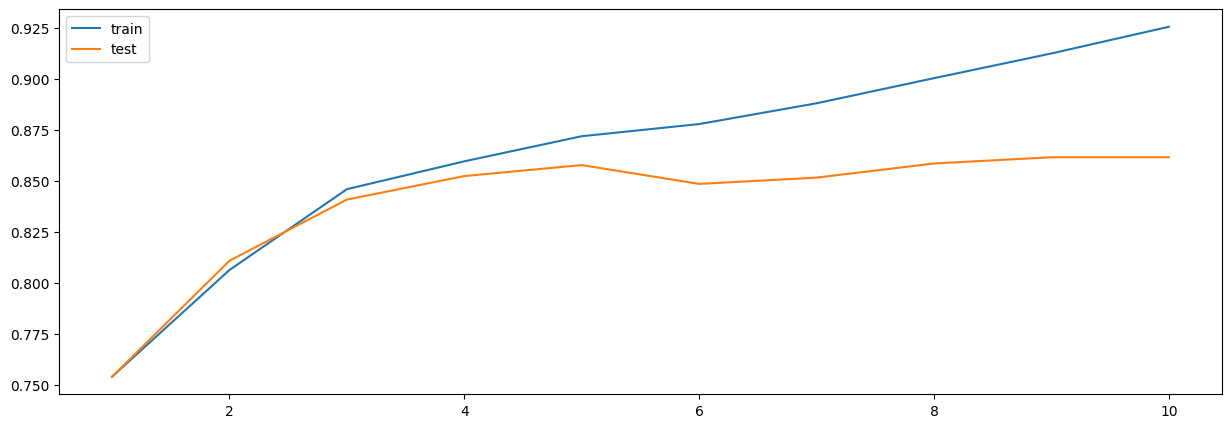

In [17]:
# 시각화 
plt.figure(figsize=(15, 5))

plt.plot(range(1, 11), train_list, label="train")
plt.plot(range(1, 11), test_list, label="test")

plt.legend()

# B) 실습 

## 1. 문제 정의 

- 버섯 데이터의 여러 특성을 활용하여 독인지 시용인지 분류 
- 결정 트리 (Decision Tree) 모델을 시각화 해보기 
- 특성 선택 (Feature Selection) 해보기 

In [18]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

## 2. 데이터 로드 및 탐색 

- 데이터: 버섯 데이터
- 포맷: csv
- feature(특성):
    - cap-shape: 갓 모양(b, c, x, f, k, s → 원뿔 / 평면 / 볼록 등)
    - cap-surface: 갓 표면(f, g, y, s → 섬유질 / 비늘모양 / 부드러움 등)
    - cap-color: 갓 색(n, b, c, g, r, p, u, e, w, y → 계피 / 회색 / 노란색 등)
    - bruises: 타박상(t, f →  예 / 아니오)
    - odor: 냄새(a, l, c, y, f, m, n, p, s → 아몬드, 생선, 매운 등)
    - gill-attachment: 자실층 위치
    - gill-spacing: 자실층 간격
    - gill-size: 자실층 크기
    - gill-color: 자실층 색
    - stalk-shape: 자루 모양
    - stalk-root: 자루 뿌리
    - stalk-surface-above-ring: 자루 표면 위 자루테
    - stalk-surface-below-ring: 자루 표면 아래 자루테
    - stalk-color-above-ring: 자루 색 위 자루테
    - stalk-color-below-ring: 자루 색 아래 자루테
    - veil-type: 베일 유형
    - veil-color: 베일 색
    - ring-number: 링 번호
    - ring-type: 링 유형
    - spore-pring-color: 포자 색
    - population: 생태적 분포도
    - habitat: 서식지
- target:
    - poisonout: 독버섯(poisonous), 식용버섯(edible)

In [19]:
df = pd.read_csv("../data/mushroom.csv")

print(df.shape)
df.head()

(8124, 23)


,poisonous,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [ ]:
df.info() # 결측치는 존재하지 않지만 모든 특성의 자료형이 object이므로 추가적으로 전처리를 진행할 필요가 있음

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   poisonous                 8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [21]:
df.isnull().sum()

poisonous                   0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

## 3. EDA (탐색적 데이터 분석)

- 기술통계
- 시각화 

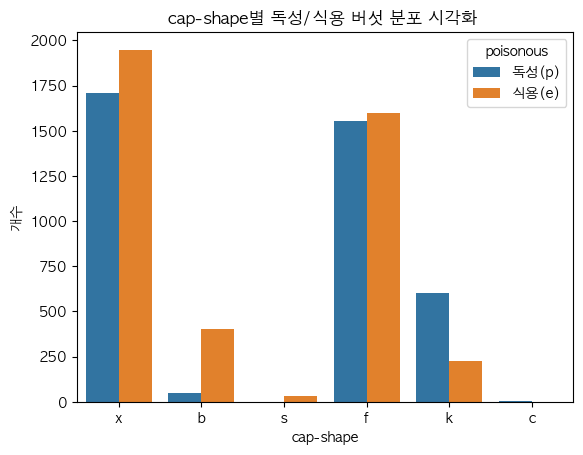

In [23]:
# cap-shape별 독성/식용 버섯 분포 시각화 

# 한글 폰트 설정
plt.rc("font", family="AppleGothic") # windows: Malgun Gothic

# 시각화 
plt.Figure(figsize=(10, 6))

sns.countplot(df, x="cap-shape", hue="poisonous")

plt.title("cap-shape별 독성/식용 버섯 분포 시각화 ")
plt.xlabel("cap-shape")
plt.ylabel("개수")
plt.legend(title="poisonous", labels=["독성(p)", "식용(e)"]);

# 차트 해설:
# cap-shape(버섯 갓의 모양)에 따라 독성(p)과 식용(e) 버섯의 분포가 다르게 나타난다.
# 대부분의 cap-shape에서 식용 버섯(e)이 독성 버섯(p)보다 더 많은 빈도를 보인다.
# 특히 'x'(convex)와 'b'(bell) 모양에서 식용 버섯이 두드러지게 많으며,
# 일부 모양에서는 독성 버섯의 비율이 상대적으로 높거나 비슷하게 나타날 수 있다.
# 하지만 cap-shape만으로 독성과 식용을 완전히 구분하기는 어려우므로,
# cap-shape는 독성 예측의 보조적 특성으로 활용될 수 있다.

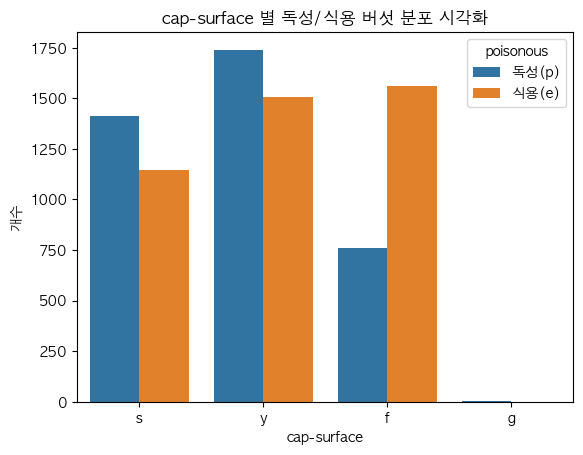

In [24]:
# cap-surface 별 독성/식용 버섯 분포 시각화 

plt.Figure(figsize=(10, 6))

sns.countplot(df, x="cap-surface", hue="poisonous")

plt.title("cap-surface 별 독성/식용 버섯 분포 시각화")
plt.xlabel("cap-surface")
plt.ylabel("개수")
plt.legend(title="poisonous", labels=["독성(p)", "식용(e)"]);

## 4. featrue, target 분리 

In [25]:
# feature와 target 분리 
X = df.drop("poisonous", axis=1)
y = df["poisonous"]

print(X.shape, y.shape)

(8124, 22) (8124,)


## 5. 전처리: 인코딩

- **라벨 인코딩(Label Encoding)**
    - 특정 문자 데이터를 0, 1, 2, ...순으로 정수 간격으로 매핑하는 방식
    - 간단한 숫자의 크고 작음에 대한 특성이 작용하므로 거리나 수치 기반 모델에 적용했을 때 성능에 대한 신뢰성이 떨어질 가능성이 있음
- **원 핫 인코딩(One-Hot Encoding)**
    - 특정 컬럼의 유니크 값에 대한 더미 컬럼들을 만들어 실제 데이터가 있는 자리에 1로 표시하고 나머지는 0으로 채워주는 방식
    - 컴퓨터는 모든 데이터를 2진수로 처리하기 때문에 라벨 인코딩에 비해 기계가 직관적으로 이해하기 쉬우며 숫자의 크고 작음에 대한 특성이 없음
    - 데이터의 유니크 값들이 많은 경우 그만큼 많은 컬럼들이 만들어져야하기 때문에 메모리 소모가 클 수 있음

In [26]:
# X 데이터에 대해 원핫인코딩을 진행하고 데이터 타입을 모두 int로 변환
X_encoded = pd.get_dummies(X).astype(int)

print("인코딩 전 shape:", X.shape)
print("인코딩 후 shape:", X_encoded.shape)

인코딩 전 shape: (8124, 22)
인코딩 후 shape: (8124, 117)


In [27]:
display(X.head())
display(X_encoded.head())

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


## 6. Train, Test 데이터 분리 

In [ ]:
# y의 클래스 분포 확인 

y.value_counts() # 클래스 불균형이 거의 없는 것을 확인 -> 그래도 모델링을 안전하게 진행할 수 있도록 stratify옵션 설정하기

poisonous
e    4208
p    3916
Name: count, dtype: int64

In [29]:
# train, test 데이터로 분리 
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

# 분리된 데이터의 클래스 분포 확인 
print(y_train.value_counts(normalize=True))
print()
print(y_test.value_counts(normalize=True))

poisonous
e    0.517939
p    0.482061
Name: proportion, dtype: float64

poisonous
e    0.518048
p    0.481952
Name: proportion, dtype: float64


In [30]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# 성능평가(정확도)
train_score = model.score(X_train, y_train)
test_score = model.score(X_test, y_test)

print("Train 정확도:", train_score)
print("Test 정확도:", test_score)

Train 정확도: 1.0
Test 정확도: 1.0


In [32]:
# 분류 평가지표 레포트로 성능을 종합적으로 확인해보기 
from sklearn.metrics import classification_report 

pred = model.predict(X_test)

print(classification_report(pred, y_test))

              precision    recall  f1-score   support

           e       1.00      1.00      1.00      1263
           p       1.00      1.00      1.00      1175

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



In [33]:
# 과적합 방지를 위해 max_depth, min_samples_split, min_samples_leaf 등의 하이퍼파라미터 설정
model2 = DecisionTreeClassifier(
    random_state=42,
    max_depth=5,            # 트리의 최대 깊이 제한 
    min_samples_split=10,   # 노드를 분할하기 위한 최소 샘플 수
    min_samples_leaf=5      # 리프 노드가 되기 위한 최소 샘플 수 (최종 결정 노드에 최소 5개의 데이터가 남아있어야함을 의미)
)

model2.fit(X_train, y_train)

print("Train 정확도:", train_score)
print("Test 정확도:", test_score)

Train 정확도: 1.0
Test 정확도: 1.0


## 8. max_depth에 따라 정확도 비교 및 시각화 

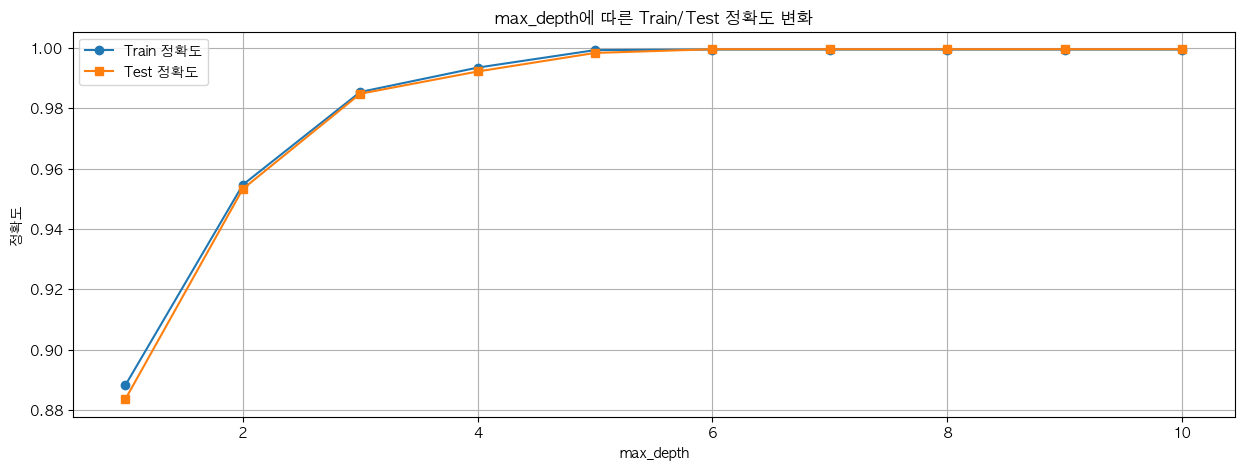

In [34]:
train_scores = []
test_scores = []
max_depth_range = range(1, 11)

for i in max_depth_range:
    model3 = DecisionTreeClassifier(max_depth=i, min_samples_split=10, min_samples_leaf=5)
    model3.fit(X_train, y_train)
    train_scores.append(model3.score(X_train, y_train))
    test_scores.append(model3.score(X_test, y_test))

# 시각화 
plt.figure(figsize=(15, 5))

plt.plot(max_depth_range, train_scores, marker="o", label="Train 정확도")
plt.plot(max_depth_range, test_scores, marker="s", label="Test 정확도")

plt.xlabel("max_depth")
plt.ylabel("정확도")
plt.title("max_depth에 따른 Train/Test 정확도 변화")
plt.legend()
plt.grid(True)

## 9. 특성 중요도 확인 

- 모델이 정답을 예측함에 있어서 특성들의 중요도를 수치로 출력할 수 있음(해당 특성이 정답 예측에 얼만큼 기여했나)
- 각 특성들은 0~1사이의 중요도 값을 가지며 모든 특성의 중요도의 합은 1이 됨 
    - 0: 모델이 정답을 예측하는 데 전혀 도움이 되지 않는 특성
    - 1: 완벽하게 정답을 예측해내는 특성
    - 1이 나오는 특성이 있다면 모델이 정답을 예측함에 있어서 해당 특성 하나로만 판단했다는 뜻 (즉, 다른 특성은 예측에 필요가 없게 됨)

In [ ]:
# 특성 중요도와 피처 이름을 매칭하여 데이터프레임 생성 
feature_importances = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model.feature_importances_
})

# 중요도 내림차순 정렬 
feature_importances = feature_importances.sort_values("importance", ascending=False)

feature_importances

# 결론 
# - tree 모델 내부 시각화 표를 보면 가장 중요도가 높은 특성인 odor_n을 가장 먼저 고려해서 분류함을 알 수 있음
# - 즉, tree모델은 중요도가 가장 높은(정답을 예측하는 데 가장 중요한) 특성을 먼저 고려해야 가장 효율적으로 
#   분류할 수 있음 
# - 현재 데이터는 학습용 데이터로 odor_n 특성이 60%이상의 중요도를 혼자 차지하고 있었기 때문에 분류 패턴과 
#   규칙을 찾기 쉬웠어서 100%에 가까운 정확도를 얻어낼 수 있었음 

,feature,importance
27,odor_n,0.620286
53,stalk-root_c,0.172606
63,stalk-surface-below-ring_y,0.100864
100,spore-print-color_r,0.036862
22,odor_a,0.023065
...,...,...
39,gill-color_g,0.000000
38,gill-color_e,0.000000
37,gill-color_b,0.000000
35,gill-size_b,0.000000
